In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("vehicalregration.csv")
df.head()

,registrationYear,financialYear,registrationMonthMMYY,makerName,stateName,rtoCode,rtoName,vehicleCategoryName,vehicleModelName,fuelName,vehicleClassName,grossVehicleWeight,pollutionNorm,saleType,vehicleCount
0,2023,2022-2023,Mar-23,HYUNDAI MOTOR INDIA LTD,Punjab,PB19,RTO BARNALA,LIGHT MOTOR VEHICLE,CRETA 1.5 CRDI MT EX,DIESEL,Motor Car,1765,BHARAT STAGE VI,Resale,1
1,2022,2021-2022,Mar-22,TVS MOTOR COMPANY LTD,Odisha,OR26,NUAPADA RTO,TWO WHEELER(NT),TVS RADEON,PETROL,M-Cycle/Scooter,246,BHARAT STAGE VI,New,3
2,2020,2020-2021,Dec-20,TOYOTA KIRLOSKAR MOTOR PVT LTD,Karnataka,KA63,DHARWAD EAST RTO,LIGHT MOTOR VEHICLE,TOYOTA URBAN CRUISER (HIGH MT),PETROL,Motor Car,1600,BHARAT STAGE VI,New,2
3,2022,2022-2023,Sep-22,MARUTI SUZUKI INDIA LTD,Chhattisgarh,CG14,Jashpur DTO,LIGHT MOTOR VEHICLE,SWIFT LXI,PETROL,Motor Car,1335,BHARAT STAGE VI,New,1
4,2023,2023-2024,Sep-23,TATA MOTORS PASSENGER VEHICLES LTD,Karnataka,KA51,ELECTRONIC CITY RTO,LIGHT MOTOR VEHICLE,HARRIER XZ+ 2LBS6PH2 #DRK,DIESEL,Motor Car,2200,BHARAT STAGE VI,New,1


In [3]:
df.shape

(500000, 15)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype
---  ------                 --------------   -----
 0   registrationYear       500000 non-null  int64
 1   financialYear          500000 non-null  str  
 2   registrationMonthMMYY  500000 non-null  str  
 3   makerName              500000 non-null  str  
 4   stateName              500000 non-null  str  
 5   rtoCode                500000 non-null  str  
 6   rtoName                500000 non-null  str  
 7   vehicleCategoryName    500000 non-null  str  
 8   vehicleModelName       499994 non-null  str  
 9   fuelName               500000 non-null  str  
 10  vehicleClassName       500000 non-null  str  
 11  grossVehicleWeight     500000 non-null  int64
 12  pollutionNorm          500000 non-null  str  
 13  saleType               500000 non-null  str  
 14  vehicleCount           500000 non-null  int64
dtypes: int64(3), str(12)
memory 

In [5]:
df.describe(include="all")

,registrationYear,financialYear,registrationMonthMMYY,makerName,stateName,rtoCode,rtoName,vehicleCategoryName,vehicleModelName,fuelName,vehicleClassName,grossVehicleWeight,pollutionNorm,saleType,vehicleCount
count,500000.000000,500000,500000,500000,500000,500000,500000,500000,499994,500000,500000,500000.000000,500000,500000,500000.000000
unique,NaN,10,73,1244,35,1173,1298,16,14160,21,67,NaN,24,2,NaN
top,NaN,2023-2024,Oct-25,MARUTI SUZUKI INDIA LTD,Tamil Nadu,TN51,PUNE,LIGHT MOTOR VEHICLE,PULSAR 150 DTS-I,PETROL,M-Cycle/Scooter,NaN,BHARAT STAGE VI,New,NaN
freq,NaN,96120,9948,60795,55877,4211,2315,219573,2935,282311,192124,NaN,415215,434793,NaN
mean,2022.823424,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1696.285062,NaN,NaN,5.613512
std,10.137112,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3861.624052,NaN,NaN,23.520600
min,2020.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,1.000000
25%,2022.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,271.000000,NaN,NaN,1.000000
50%,2023.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1185.000000,NaN,NaN,1.000000
75%,2024.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1740.000000,NaN,NaN,3.000000


In [6]:
df.isnull().sum()

registrationYear         0
financialYear            0
registrationMonthMMYY    0
makerName                0
stateName                0
rtoCode                  0
rtoName                  0
vehicleCategoryName      0
vehicleModelName         6
fuelName                 0
vehicleClassName         0
grossVehicleWeight       0
pollutionNorm            0
saleType                 0
vehicleCount             0
dtype: int64

In [7]:
df.columns

Index(['registrationYear', 'financialYear', 'registrationMonthMMYY',
       'makerName', 'stateName', 'rtoCode', 'rtoName', 'vehicleCategoryName',
       'vehicleModelName', 'fuelName', 'vehicleClassName',
       'grossVehicleWeight', 'pollutionNorm', 'saleType', 'vehicleCount'],
      dtype='str')

In [8]:
df = df.drop_duplicates()

df["registrationMonthMMYY"] = pd.to_datetime(
    df["registrationMonthMMYY"],
    format="%b-%y",
    errors="coerce"
)

df["registrationMonth"] = df["registrationMonthMMYY"].dt.month

df = df.drop(columns=[
    "registrationMonthMMYY",
    "financialYear"
])

In [9]:
features = [
    "registrationYear",
    "registrationMonth",
    "grossVehicleWeight",
    "vehicleCategoryName",
    "fuelName",
    "stateName",
    "saleType",
    "pollutionNorm"
]

X = df[features]
y = df["vehicleCount"]

print(X.shape)
print(y.shape)

(500000, 8)
(500000,)


In [10]:
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(include="object").columns

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

C:\Users\YASH\AppData\Local\Temp\ipykernel_23528\4029689997.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (400000, 8)
Testing: (100000, 8)


In [12]:
results = []

def evaluate(name, model):
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append([name, mae, mse, rmse, r2])

    print("Model:", name)
    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R2 Score:", r2)

    return y_pred

In [13]:
lr = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

lr_pred = evaluate("Linear Regression", lr)

Model: Linear Regression
MAE: 6.5908601831928015
MSE: 528.2703768584048
RMSE: 22.984133154382935
R2 Score: 0.040503857320714154


In [14]:
lasso = Pipeline([
    ("preprocessing", preprocessor),
    ("model", Lasso(alpha=0.1, max_iter=5000))
])

lasso_pred = evaluate("Lasso Regression", lasso)

Model: Lasso Regression
MAE: 6.294551910014085
MSE: 531.4122488503573
RMSE: 23.05238054627672
R2 Score: 0.03479728320804443


In [15]:
dt = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ))
])

dt_pred = evaluate("Decision Tree", dt)

Model: Decision Tree
MAE: 5.74822727406575
MSE: 513.5947826569774
RMSE: 22.662629650086448
R2 Score: 0.06715910176492479


In [16]:
rf = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=50,
        max_depth=12,
        n_jobs=-1,
        random_state=42
    ))
])

rf_pred = evaluate("Random Forest", rf)

Model: Random Forest
MAE: 5.632270878601237
MSE: 496.4963065008066
RMSE: 22.282197075261823
R2 Score: 0.09821502054482079


In [17]:
X_simple = df[["grossVehicleWeight"]]
y_simple = df["vehicleCount"]

X_simple = X_simple.fillna(X_simple.median())

xs_train, xs_test, ys_train, ys_test = train_test_split(
    X_simple, y_simple,
    test_size=0.2,
    random_state=42
)

simple_lr = LinearRegression()
simple_lr.fit(xs_train, ys_train)

simple_pred = simple_lr.predict(xs_test)

print("R2 Score:", r2_score(ys_test, simple_pred))
print("RMSE:", np.sqrt(mean_squared_error(ys_test, simple_pred)))

R2 Score: 0.002668944190743705
RMSE: 23.432907802300964


In [18]:
poly_model = Pipeline([
    ("poly", PolynomialFeatures(degree=2)),
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

poly_model.fit(xs_train, ys_train)

poly_pred = poly_model.predict(xs_test)

print("R2 Score:", r2_score(ys_test, poly_pred))
print("MAE:", mean_absolute_error(ys_test, poly_pred))
print("RMSE:", np.sqrt(mean_squared_error(ys_test, poly_pred)))

R2 Score: 0.00816613522710996
MAE: 6.646256639192677
RMSE: 23.368238620984947


In [19]:
comparison = pd.DataFrame(
    results,
    columns=["Model", "MAE", "MSE", "RMSE", "R2 Score"]
)

comparison.sort_values(by="R2 Score", ascending=False)

,Model,MAE,MSE,RMSE,R2 Score
3,Random Forest,5.632271,496.496307,22.282197,0.098215
2,Decision Tree,5.748227,513.594783,22.662630,0.067159
0,Linear Regression,6.590860,528.270377,22.984133,0.040504
1,Lasso Regression,6.294552,531.412249,23.052381,0.034797


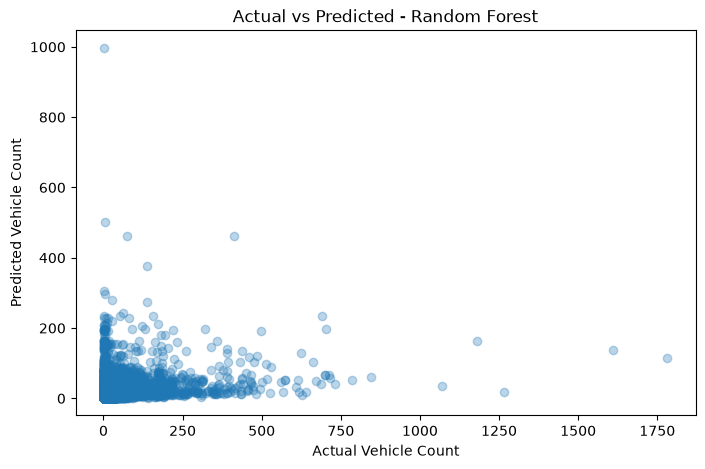

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_pred, alpha=0.3)

plt.xlabel("Actual Vehicle Count")
plt.ylabel("Predicted Vehicle Count")
plt.title("Actual vs Predicted - Random Forest")

plt.show()

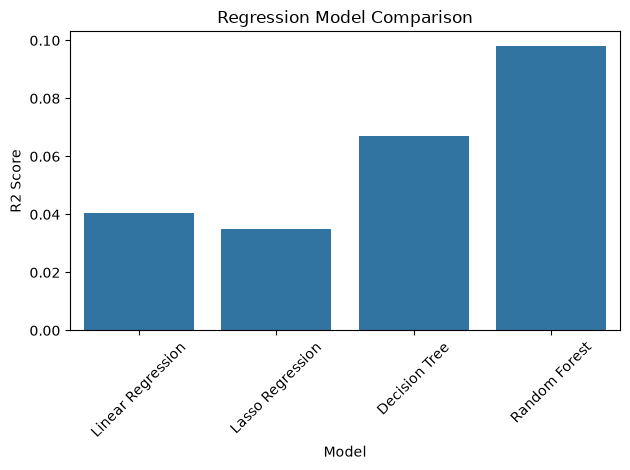

In [21]:
sns.barplot(
    data=comparison,
    x="Model",
    y="R2 Score"
)

plt.xticks(rotation=45)
plt.title("Regression Model Comparison")
plt.tight_layout()
plt.show()

In [22]:
new_data = pd.DataFrame({
    "registrationYear": [2024],
    "registrationMonth": [6],
    "grossVehicleWeight": [1500],
    "vehicleCategoryName": ["LIGHT MOTOR VEHICLE"],
    "fuelName": ["PETROL"],
    "stateName": ["Gujarat"],
    "saleType": ["New"],
    "pollutionNorm": ["BHARAT STAGE VI"]
})

prediction = rf.predict(new_data)

print("Predicted Vehicle Count:", max(0, round(prediction[0])))

Predicted Vehicle Count: 2
